# Ensemble Learning Lab: Bagging, AdaBoost, Random Forest

In [1]:
# Common imports and helper functions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier


def evaluate_model(clf, X_test, y_test, pos_label=1):
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    auc = None
    if hasattr(clf, "predict_proba"):
        y_proba = clf.predict_proba(X_test)[:, pos_label]
        try:
            auc = roc_auc_score(y_test, y_proba)
        except Exception:
            auc = None
    return {"accuracy": acc, "roc_auc": auc}

# Dataset loading

In [2]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [3]:
len(y_train[y_train == 0]), len(y_train[y_train == 1])

(148, 250)

# Constants

In [4]:
max_depth = 7
random_state = 81

# Classifiers training

In [5]:
# Bagging example: compare single tree vs bagged trees
base = DecisionTreeClassifier(max_depth=max_depth, random_state=random_state)
base.fit(X_train, y_train)

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=max_depth),
    n_estimators=200,
    bootstrap=True,
    oob_score=True,
    random_state=random_state,
    n_jobs=-1
)

bag.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...r(max_depth=7)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",200
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",True
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary `... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",81
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [6]:
# AdaBoost example
base_ada = DecisionTreeClassifier(max_depth=max_depth, random_state=random_state)
base_ada.fit(X_train, y_train)

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=max_depth, random_state=random_state),
    n_estimators=200,
    learning_rate=1.0,
    random_state=0
)

ada.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=81)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",200
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None


In [7]:
# Random Forest example
rf = RandomForestClassifier(
    n_estimators=200,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    random_state=random_state,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

# Model evaluations and comparisons

Train evals:
Base: {'accuracy': 1.0, 'roc_auc': 1.0}
Bagging: {'accuracy': 1.0, 'roc_auc': 1.0}
AdaBoost: {'accuracy': 1.0, 'roc_auc': 1.0}
RandomForest: {'accuracy': 1.0, 'roc_auc': 1.0}


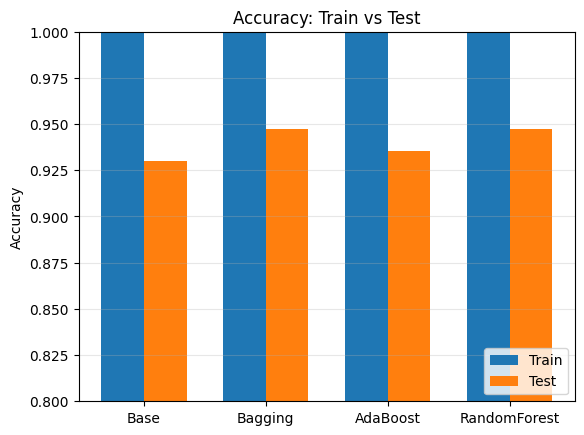

C:\Users\Raffaele\AppData\Local\Temp\ipykernel_152432\284611783.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower right")


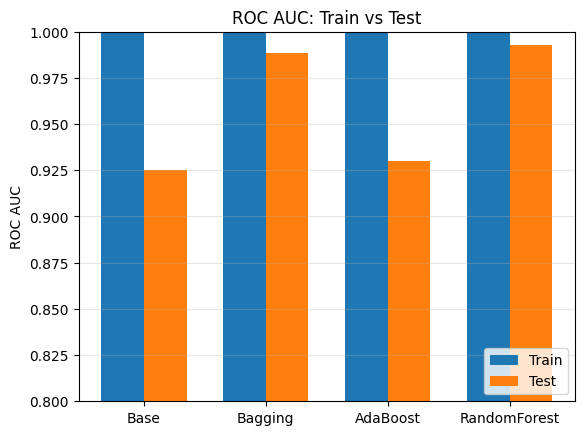

In [8]:
# Compute training-set evaluations for all models
base_train_eval = evaluate_model(base, X_train, y_train)
bag_train_eval = evaluate_model(bag, X_train, y_train)
ada_train_eval = evaluate_model(ada, X_train, y_train)
rf_train_eval = evaluate_model(rf, X_train, y_train)
base_test_eval = evaluate_model(base, X_test, y_test)
bag_test_eval = evaluate_model(bag, X_test, y_test)
ada_test_eval = evaluate_model(ada, X_test, y_test)
rf_test_eval = evaluate_model(rf, X_test, y_test)


print("Train evals:")
print("Base:", base_train_eval)
print("Bagging:", bag_train_eval)
print("AdaBoost:", ada_train_eval)
print("RandomForest:", rf_train_eval)
"""
Train vs Test Accuracy comparison plot
"""
models = ['Base', 'Bagging', 'AdaBoost', 'RandomForest']
train_acc = [base_train_eval['accuracy'], bag_train_eval['accuracy'], ada_train_eval['accuracy'], rf_train_eval['accuracy']]
test_acc = [base_test_eval['accuracy'], bag_test_eval['accuracy'], ada_test_eval['accuracy'], rf_test_eval['accuracy']]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots()
ax.bar(x - width/2, train_acc, width, label='Train')
ax.bar(x + width/2, test_acc, width, label='Test')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('Accuracy')
ax.set_ylim(0.8, 1.0)
ax.set_title('Accuracy: Train vs Test')
ax.legend(loc="lower right")
ax.grid(True, axis='y', alpha=0.3)
plt.show()
"""
Train vs Test ROC AUC comparison plot
"""

train_auc = [
    base_train_eval['roc_auc'],
    bag_train_eval['roc_auc'],
    ada_train_eval['roc_auc'],
    rf_train_eval['roc_auc']
]

test_auc = [
    base_test_eval['roc_auc'],
    bag_test_eval['roc_auc'],
    ada_test_eval['roc_auc'],
    rf_test_eval['roc_auc']
]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots()
ax.legend(loc="lower right")

ax.bar(x - width/2, train_auc, width, label='Train')
ax.bar(x + width/2, test_auc, width, label='Test')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('ROC AUC')
ax.set_ylim(0.8, 1.0)
ax.set_title('ROC AUC: Train vs Test')
ax.grid(True, axis='y', alpha=0.3)
ax.legend(loc="lower right")
plt.show()

# Comparison as T grows

In [9]:
# Sweep n_estimators example (cross-validated) and plot results
import pandas as pd

def sweep_n_estimators(clf_builder, n_est_values, X, y, cv=5):
    results = []
    for n in n_est_values:
        clf = clf_builder(n)
        scores = cross_val_score(clf, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
        results.append((n, scores.mean(), scores.std()))
    return pd.DataFrame(results, columns=['n', 'mean_acc', 'std_acc'])

n_values = [1, 10,50,100,150, 200, 300, 400, 500]
res_rf = sweep_n_estimators(lambda n: RandomForestClassifier(n_estimators=n), n_values , X_train, y_train, cv=5)
res_ada = sweep_n_estimators(lambda n: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=max_depth), n_estimators=n), n_values, X_train, y_train, cv=5)
res_bag = sweep_n_estimators(lambda n: BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=max_depth), n_estimators=n), n_values, X_train, y_train, cv=5)

Random Forests:
     n  mean_acc   std_acc
0    1  0.914589  0.009223
1   10  0.967437  0.024476
2   50  0.959937  0.030994
3  100  0.967500  0.038406
4  150  0.962437  0.032548
5  200  0.970000  0.034095
6  300  0.970000  0.032210
7  400  0.972500  0.032977
8  500  0.972500  0.032977
AdaBoost
     n  mean_acc   std_acc
0    1  0.934778  0.028785
1   10  0.932342  0.037436
2   50  0.927247  0.034681
3  100  0.929747  0.030041
4  150  0.927152  0.024262
5  200  0.934810  0.033758
6  300  0.924684  0.028396
7  400  0.934778  0.034692
8  500  0.929778  0.034840
Bagging
     n  mean_acc   std_acc
0    1  0.932184  0.034075
1   10  0.957405  0.032147
2   50  0.965000  0.038243
3  100  0.962437  0.031573
4  150  0.962468  0.036207
5  200  0.964968  0.033891
6  300  0.967468  0.032191
7  400  0.967468  0.032191
8  500  0.962405  0.028449


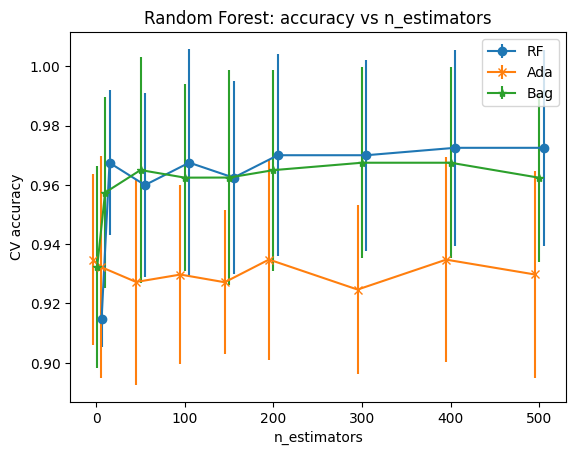

In [10]:

print("Random Forests:")
print(res_rf)

print("AdaBoost")
print(res_ada)

print("Bagging")
print(res_bag)

# Plot results, with error bars, error_bars should be affected by a little scattering for visibility
plt.errorbar(res_rf['n']+5, res_rf['mean_acc'], yerr=res_rf['std_acc'], marker='o', label="RF")
plt.errorbar(res_ada['n']-5, res_ada['mean_acc'], yerr=res_ada['std_acc'], marker='x', label="Ada")
plt.errorbar(res_bag['n'], res_bag['mean_acc'], yerr=res_bag['std_acc'], marker='*', label="Bag")

plt.xlabel('n_estimators')
plt.ylabel('CV accuracy')
plt.title('Random Forest: accuracy vs n_estimators')
plt.legend()
plt.show()